# NERMuD 2023 — Exploratory Data Analysis

This notebook provides a concise exploratory analysis of the processed NERMuD 2023 dataset.

The analysis focuses on:

- dataset size and split distribution;
- domain distribution;
- named entity type distribution;
- entity distribution across domains;
- BIO label distribution;
- sequence length.

The purpose of this analysis is to understand the characteristics of the dataset before fine-tuning Transformer models for Italian Named Entity Recognition.

## 1. Imports and Setup

Standard libraries (`json`, `pathlib`, `collections`) and data-science stack (`pandas`, `matplotlib`, `seaborn`) are imported. The helper `load_jsonl` re-reads the processed files produced by `01_preprocessing.ipynb`.

In [23]:
import json
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

In [24]:
PROCESSED_DIR = Path("../data/processed")

def load_jsonl(filepath):
    data = []

    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            data.append(json.loads(line))

    return data

## 2. Load Processed Datasets

The three processed JSONL files are loaded from `data/processed/`. After loading:

| Split | Samples |
|-------|---------|
| Train | 27,482  |
| Dev   |  4,767  |
| Test  |  4,126  |

Each sample is a dictionary with keys `tokens`, `labels`, and `domain`.

In [25]:
train_data = load_jsonl(PROCESSED_DIR / "train.jsonl")
dev_data = load_jsonl(PROCESSED_DIR / "dev.jsonl")
test_data = load_jsonl(PROCESSED_DIR / "test.jsonl")

dataset_overview = pd.DataFrame({
    "Split": ["Train", "Dev", "Test"],
    "Samples": [
        len(train_data),
        len(dev_data),
        len(test_data)
    ]
})

dataset_overview["Percentage"] = (
    dataset_overview["Samples"]
    / dataset_overview["Samples"].sum()
    * 100
)

dataset_overview

,Split,Samples,Percentage
0,Train,27482,75.551890
1,Dev,4767,13.105155
2,Test,4126,11.342955


## 3. Domain Distribution

Each split is distributed across three domains:

| Domain | Description |
|--------|-------------|
| **WN** | Wikinews — online news articles |
| **FIC** | Fiction — literary text |
| **ADG** | Alcide De Gasperi — historical political speeches |

WN and FIC dominate; ADG is substantially smaller. This imbalance must be kept in mind when interpreting per-domain model performance: the model sees far fewer ADG examples during training.

In [26]:
def get_domain_counts(data):
    return Counter(
        sample["domain"]
        for sample in data
    )
    
train_domains = get_domain_counts(train_data)
dev_domains = get_domain_counts(dev_data)
test_domains = get_domain_counts(test_data)

domain_overview = pd.DataFrame({
    "Train": train_domains,
    "Dev": dev_domains,
    "Test": test_domains
}).fillna(0).astype(int)

domain_overview

,Train,Dev,Test
adg,5147,1122,521
fic,11423,1051,1517
wn,10912,2594,2088


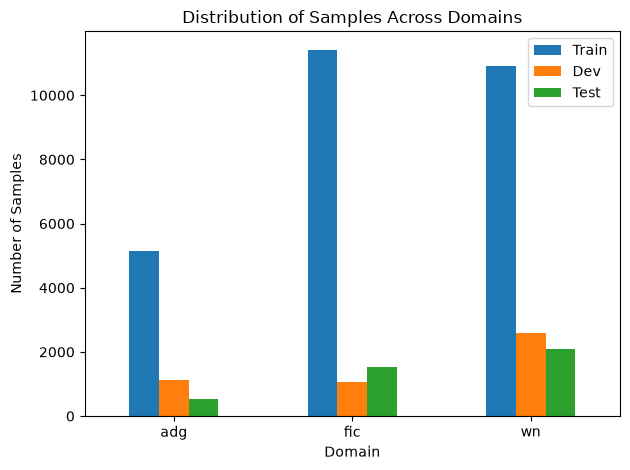

In [27]:
domain_overview.plot(kind="bar")

plt.title("Distribution of Samples Across Domains")
plt.xlabel("Domain")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 4. Entity Type Distribution

Named entities are counted by type (`PER`, `ORG`, `LOC`) across all splits. Key figures from the training set:

| Type | Training Entities |
|------|-------------------|
| PER  | 9,391 |
| LOC  | 6,302 |
| ORG  | 6,122 |

**PER** (Person) is the most frequent entity type — which correlates with the higher per-entity F1 scores observed at evaluation time. **ORG** is the least frequent and the hardest for the models.

In [28]:
def count_entities(data):
    counts = Counter()

    for sample in data:
        for label in sample["labels"]:
            if label.startswith("B-"):
                entity_type = label[2:]
                counts[entity_type] += 1

    return counts

train_entities = count_entities(train_data)
dev_entities = count_entities(dev_data)
test_entities = count_entities(test_data)

entity_overview = pd.DataFrame({
    "Train": train_entities,
    "Dev": dev_entities,
    "Test": test_entities
}).fillna(0).astype(int)

entity_overview

,Train,Dev,Test
ORG,6122,1628,1487
LOC,6302,1892,990
PER,9391,1698,1959


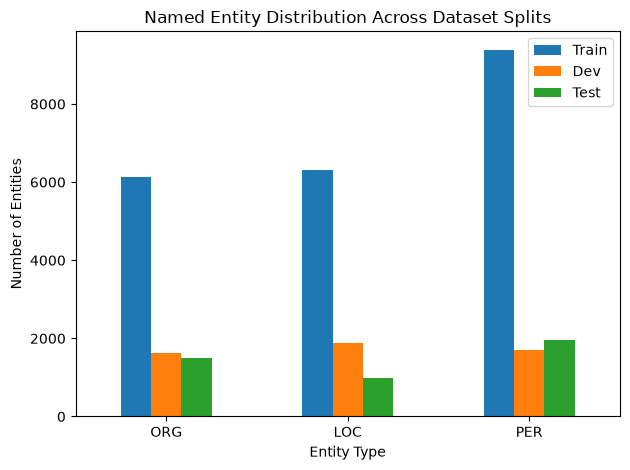

In [29]:
entity_overview.plot(kind="bar")

plt.title("Named Entity Distribution Across Dataset Splits")
plt.xlabel("Entity Type")
plt.ylabel("Number of Entities")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 5. Entity Distribution by Domain

The entity type mix differs substantially across domains:

- **FIC** contains many `PER` entities (characters in fiction) but very few `ORG` entities.
- **WN** has a more balanced mix of all three types.
- **ADG** features many `PER` and `LOC` references (political speeches mention people and places), but very few `ORG`.

This domain-level variation helps explain model performance differences when evaluated per domain.

In [30]:
def count_entities_by_domain(data):
    counts = Counter()

    for sample in data:
        domain = sample["domain"]

        for label in sample["labels"]:
            if label.startswith("B-"):
                entity_type = label[2:]
                counts[(domain, entity_type)] += 1

    return counts

train_domain_entities = count_entities_by_domain(train_data)

In [31]:
domain_entity_df = pd.DataFrame(
    [
        {
            "Domain": domain,
            "Entity Type": entity_type,
            "Count": count
        }
        for (domain, entity_type), count
        in train_domain_entities.items()
    ]
)

domain_entity_df

,Domain,Entity Type,Count
0,adg,ORG,1531
1,adg,LOC,915
2,adg,PER,889
3,fic,LOC,587
4,fic,PER,3177
5,fic,ORG,137
6,wn,LOC,4800
7,wn,PER,5325
8,wn,ORG,4454


In [32]:
domain_entity_pivot = domain_entity_df.pivot(
    index="Domain",
    columns="Entity Type",
    values="Count"
).fillna(0).astype(int)

domain_entity_pivot

Entity Type,LOC,ORG,PER
Domain,,,
adg,915,1531,889
fic,587,137,3177
wn,4800,4454,5325


In [33]:
domain_entity_pivot = domain_entity_df.pivot(
    index="Domain",
    columns="Entity Type",
    values="Count"
).fillna(0).astype(int)

domain_entity_pivot

Entity Type,LOC,ORG,PER
Domain,,,
adg,915,1531,889
fic,587,137,3177
wn,4800,4454,5325


## 6. BIO Label Distribution

Beyond entity types, it is useful to examine the distribution of raw BIO labels:

- `O` — outside any entity (overwhelmingly dominant, reflecting natural text)
- `B-PER`, `I-PER`, `B-ORG`, `I-ORG`, `B-LOC`, `I-LOC`

A highly skewed distribution (many `O` vs few entity labels) is typical for NER tasks and motivates the use of **seqeval** for evaluation, which measures entity-span accuracy rather than per-token accuracy.

In [34]:
def count_bio_labels(data):
    counts = Counter()

    for sample in data:
        counts.update(sample["labels"])

    return counts

In [35]:
train_bio = count_bio_labels(train_data)
dev_bio = count_bio_labels(dev_data)
test_bio = count_bio_labels(test_data)

bio_overview = pd.DataFrame({
    "Train": train_bio,
    "Dev": dev_bio,
    "Test": test_bio
}).fillna(0).astype(int)

bio_overview

,Train,Dev,Test
O,528748,103635,94029
B-ORG,6122,1628,1487
I-ORG,4485,1097,876
B-LOC,6302,1892,990
B-PER,9391,1698,1959
I-LOC,2708,668,459
I-PER,4425,1069,1073


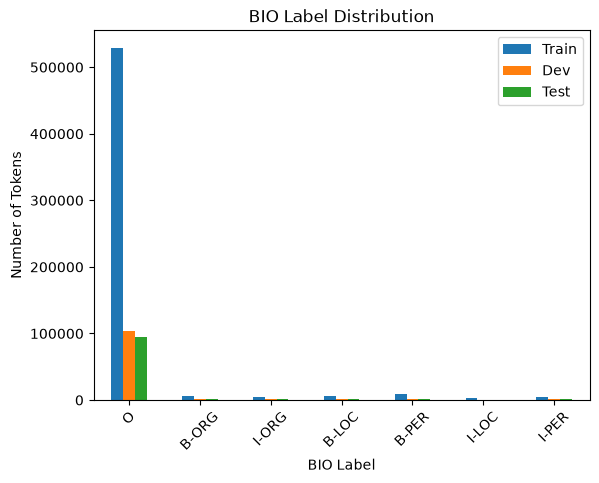

In [36]:
bio_overview.plot(kind="bar")

plt.title("BIO Label Distribution")
plt.xlabel("BIO Label")
plt.ylabel("Number of Tokens")
plt.xticks(rotation=45)

plt.show()

## 7. Sequence Length Analysis

Transformer models require a fixed `max_length` at tokenisation time. To choose this value, we analyse the distribution of token-level sequence lengths in the training data.

Key finding: the **maximum sequence length is 251 tokens**, which directly informed the choice of `max_length = 256` used in both training notebooks. This value comfortably covers 100 % of training sequences while leaving a small buffer for the special `[CLS]` and `[SEP]` tokens added by the Transformer tokeniser.

In [37]:
train_lengths = [
    len(sample["tokens"])
    for sample in train_data
]

dev_lengths = [
    len(sample["tokens"])
    for sample in dev_data
]

test_lengths = [
    len(sample["tokens"])
    for sample in test_data
]

In [38]:
length_statistics = pd.DataFrame({
    "Train": pd.Series(train_lengths).describe(),
    "Dev": pd.Series(dev_lengths).describe(),
    "Test": pd.Series(test_lengths).describe()
})

length_statistics

,Train,Dev,Test
count,27482.000000,4767.000000,4126.000000
mean,20.456335,23.429201,24.448134
std,15.778476,16.448803,17.827554
min,1.000000,1.000000,1.000000
25%,9.000000,11.000000,11.000000
50%,17.000000,20.000000,21.000000
75%,28.000000,32.000000,34.000000
max,251.000000,130.000000,137.000000


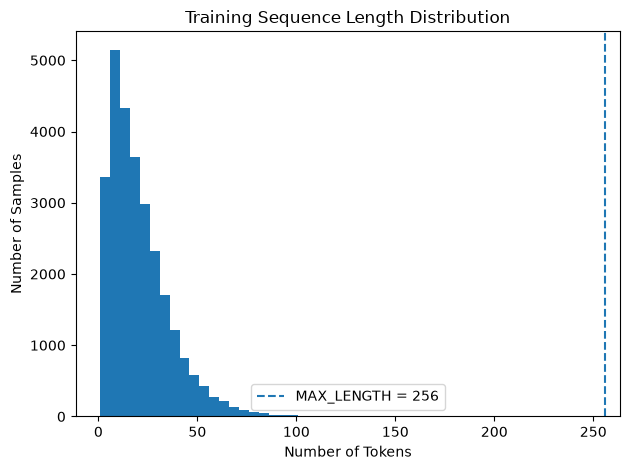

In [41]:
import sys

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    SEED,
    MODEL_1,
    MAX_LENGTH,
    LEARNING_RATE,
    BATCH_SIZE,
    NUM_EPOCHS,
    WEIGHT_DECAY,
    LABEL_NAMES,
    LABEL2ID,
    ID2LABEL,
    set_seed,
)

plt.hist(train_lengths, bins=50)

plt.axvline(
    MAX_LENGTH,
    linestyle="--",
    label=f"MAX_LENGTH = {MAX_LENGTH}"
)

plt.title("Training Sequence Length Distribution")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Samples")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def percentage_below(lengths, max_length):
    return sum(
        length <= max_length
        for length in lengths
    ) / len(lengths) * 100
    
for max_length in [64, 128, 256, 512]:
    percentage = percentage_below(train_lengths, max_length)

    print(
        f"{max_length:>3} tokens: "
        f"{percentage:.2f}% of training samples"
    )

 64 tokens: 98.19% of training samples
128 tokens: 99.96% of training samples
256 tokens: 100.00% of training samples
512 tokens: 100.00% of training samples


In [ ]:
domain_lengths = {}

for domain in ["adg", "fic", "wn"]:

    lengths = [
        len(sample["tokens"])
        for sample in train_data
        if sample["domain"] == domain
    ]

    domain_lengths[domain] = {
        "Mean": sum(lengths) / len(lengths),
        "Median": pd.Series(lengths).median(),
        "Max": max(lengths)
    }

domain_length_df = pd.DataFrame(domain_lengths).T

domain_length_df

,Mean,Median,Max
adg,24.755974,20.0,178.0
fic,15.430973,12.0,112.0
wn,23.688966,21.0,251.0


## 8. Label Vocabulary

For reference, the complete sorted label set used in the BIO encoding is printed below. This list is used to build the `label2id` / `id2label` mappings required by the Transformer models.

In [ ]:
all_labels = sorted(
    set(
        label
        for sample in train_data
        for label in sample["labels"]
    )
)

print("Number of labels:", len(all_labels))
print("Labels:", all_labels)

Number of labels: 7
Labels: ['B-LOC', 'B-ORG', 'B-PER', 'I-LOC', 'I-ORG', 'I-PER', 'O']
